# Do the models keep making the same mistakes?

Every fold model saved its predictions on the test fold in MLflow: 12 models, 5 folds each, all tested on the same 656 patches (fold 5). This notebook reads them and asks whether the errors are the same patches, pictures and patients whatever the model is, or whether each model fails in its own way.

Run it from the training repository with `uv run jupyter lab notebooks/errors.ipynb`. The first run downloads the predictions and keeps a copy in `notebooks/cache` (delete that file to download again). Change `EXPERIMENT` to read another experiment, for example `ndb_ufes_exp1`. MLflow has to be running, with the tunnel closed or open, it does not matter: the notebook reads from the server on this computer.

In [1]:
import os
import shutil
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.metrics import balanced_accuracy_score

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from src.config import load_env

EXPERIMENT = "ndb_ufes_exp2"
CACHE = REPO / "notebooks" / "cache"
PATCHES = REPO.parent / "ndb_ufes_data_organizer" / "data/ndb_ufes/patch_level/images"
CLASSES = ["Without dysplasia", "With dysplasia", "OSCC"]  # the class numbers 0, 1, 2
PROBABILITIES = ["prob_leukoplakia_without_dysplasia", "prob_leukoplakia_with_dysplasia", "prob_oscc"]

os.environ.setdefault("MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR", "false")
load_env(REPO / ".env", Path(os.getenv("MLFLOW_ENV_FILE", REPO.parent / "ndb_ufes_mlflow" / ".env")))
mlflow.set_tracking_uri(os.getenv("MLFLOW_TRACKING_URI", "http://localhost:8000/"))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

/Users/beamaia/thesis_organization/ndb_ufes_training_pipeline/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/beamaia/thesis_organization/ndb_ufes_training_pipeline/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


## 1. Load the predictions

One row for each patch and each fold run. `wrong` says whether that run got the patch wrong.

In [2]:
def load_predictions(experiment: str) -> pd.DataFrame:
    cache = CACHE / f"{experiment}.csv"
    if cache.exists():
        return pd.read_csv(cache, keep_default_na=False)
    CACHE.mkdir(parents=True, exist_ok=True)
    runs = mlflow.search_runs(experiment_names=[experiment], filter_string="attributes.status = 'FINISHED'")
    folds = runs[runs["tags.mlflow.parentRunId"].notna()]
    frames = []
    for _, run in folds.iterrows():
        path = mlflow.artifacts.download_artifacts(run_id=run["run_id"], artifact_path="heldout_predictions/predictions.csv", dst_path=str(CACHE / "download" / run["run_id"]))
        frames.append(pd.read_csv(path, keep_default_na=False).assign(validation_fold=int(run["tags.validation_fold"])))
    frame = pd.concat(frames, ignore_index=True)
    frame.to_csv(cache, index=False)
    shutil.rmtree(CACHE / "download", ignore_errors=True)
    return frame


data = load_predictions(EXPERIMENT)
data["y_true"], data["y_pred"] = data["y_true"].astype(int), data["y_pred"].astype(int)
data["wrong"] = data["y_true"] != data["y_pred"]
data["true_name"] = data["y_true"].map(dict(enumerate(CLASSES)))
data["pred_name"] = data["y_pred"].map(dict(enumerate(CLASSES)))
data["ndb"] = data["ndb_diagnosis"].replace("", "not in NDB-UFES")
data["run"] = data["model"] + "_fold" + data["validation_fold"].astype(str)
print(f"{len(data)} predictions: {data['run'].nunique()} fold runs of {data['model'].nunique()} models, {data['patch_id'].nunique()} test patches, {data['histopath_id'].nunique()} pictures, {data['case_group'].nunique()} patients")

39360 predictions: 60 fold runs of 12 models, 656 test patches, 39 pictures, 10 patients


## 2. How often is each model wrong?

The balanced accuracy of every fold run, the mean over the five folds of a model, and the share of patches it gets wrong.

In [6]:
balanced = data.groupby(["model", "validation_fold"]).apply(lambda g: balanced_accuracy_score(g["y_true"], g["y_pred"]), include_groups=False).rename("balanced_accuracy")
summary_balanced = balanced.groupby("model").agg(mean="mean", std=lambda scores: scores.std(ddof=0)).mul(100).round(1)
summary_balanced["wrong patches %"] = (data.groupby("model")["wrong"].mean() * 100).round(1)
summary_balanced.sort_values("mean", ascending=False)

,mean,std,wrong patches %
model,,,
swin_tiny_patch4_window7_224,61.4,1.6,43.5
vit_small_patch16_384,61.1,3.2,41.9
pit_s_distilled_224,59.7,2.6,44.9
vgg16,58.7,1.7,43.3
coat_lite_small,58.5,2.2,43.7
mobilenetv2,58.4,3.0,45.5
densenet121,58.3,3.4,45.9
convnext_large,57.7,2.8,45.1
swin_base_patch4_window7_224,57.6,3.4,45.9


In [7]:
summary_min = balanced.groupby("model").agg(mean="min", std=lambda scores: scores.std(ddof=0)).mul(100).round(1)
summary_max = balanced.groupby("model").agg(mean="max", std=lambda scores: scores.std(ddof=0)).mul(100).round(1)

In [8]:
summary_min

,mean,std
model,,
coat_lite_small,54.5,2.2
convnext_large,54.4,2.8
densenet121,52.9,3.4
efficientnet_b0,51.8,2.9
efficientnet_b3,51.5,1.6
mobilenetv2,54.5,3.0
pit_s_distilled_224,55.0,2.6
resnet50,53.2,1.3
swin_base_patch4_window7_224,52.2,3.4


In [9]:
summary_max

,mean,std
model,,
coat_lite_small,61.2,2.2
convnext_large,61.5,2.8
densenet121,62.4,3.4
efficientnet_b0,59.9,2.9
efficientnet_b3,56.3,1.6
mobilenetv2,61.7,3.0
pit_s_distilled_224,62.0,2.6
resnet50,57.0,1.3
swin_base_patch4_window7_224,62.5,3.4


## 3. Is it the same patches?

For every patch, in how many of the 60 fold runs is it wrong? If the models failed at random, each patch would be wrong in about the same share of the runs, and the histogram would be narrow. If some patches are hard for everybody, there are patches that are almost always wrong and others that almost never are, and the histogram stretches to both ends.

The grey bars are what the same number of errors would look like if every run put its errors on random patches of the same true class.

In [25]:
MODEL_MAJORITY = 3  # for the levels below: a model got a patch wrong when it did in at least this many of its folds
FOLD_MAJORITY = 6   # for the levels below: a fold got a patch wrong when at least this many of the models did in that fold

# runs x patches: True where that fold run got the patch wrong
wrong = data.pivot_table(index="run", columns="patch_id", values="wrong", aggfunc="first").astype(bool)

# one row for each patch: what it is, and how the fold runs did on it
patches = data.drop_duplicates("patch_id").set_index("patch_id").loc[wrong.columns, ["true_name", "y_true", "histopath_id", "case_group", "ndb"]]
patches["errors"] = wrong.sum(axis=0)  # how many of the runs got it wrong
patches["error_rate"] = patches["errors"] / len(wrong)

wrong_by_run = data.pivot_table(index="patch_id", columns=["model", "validation_fold"], values="wrong", aggfunc="first").astype(int).loc[patches.index]
n_folds = data["validation_fold"].nunique()
folds_per_model = wrong_by_run.T.groupby(level="model").sum().T  # patches x models: in how many of its folds the model got the patch wrong
models_per_fold = wrong_by_run.T.groupby(level="validation_fold").sum().T  # patches x folds: how many models got the patch wrong in that fold

# how many models, and how many folds, got the patch wrong at least once
patches["models_any_wrong"] = (folds_per_model >= 1).sum(axis=1)
patches["folds_any_wrong"] = (models_per_fold >= 1).sum(axis=1)
patches["which_models"] = folds_per_model.apply(lambda row: ", ".join(row.index[row >= 1]), axis=1)
patches["which_folds"] = models_per_fold.apply(lambda row: ", ".join(str(fold) for fold in row.index[row >= 1]), axis=1)

# the stricter counts, used by the levels further down
patches["models_wrong"] = (folds_per_model >= MODEL_MAJORITY).sum(axis=1)  # models that got it wrong in at least MODEL_MAJORITY folds
patches["models_always_wrong"] = (folds_per_model == n_folds).sum(axis=1)  # models that got it wrong in all their folds
patches["folds_wrong"] = (models_per_fold >= FOLD_MAJORITY).sum(axis=1)  # folds in which at least FOLD_MAJORITY models got it wrong

per_patch = patches[["true_name", "histopath_id", "ndb", "models_any_wrong", "folds_any_wrong", "which_models", "which_folds"]]
per_patch = per_patch.sort_values(["models_any_wrong", "folds_any_wrong"], ascending=False)
display(per_patch)
print(len(per_patch), "patches; the models are counted over", n_folds, "folds each")
print("rows: models that got the patch wrong in at least one fold; columns: folds in which at least one model got it wrong")
display(pd.crosstab(patches["models_any_wrong"], patches["folds_any_wrong"]))

,true_name,histopath_id,ndb,models_any_wrong,folds_any_wrong,which_models,which_folds
patch_id,,,,,,,
p0000,OSCC,hp_0f9423fcd3b1,not in NDB-UFES,12,5,"coat_lite_small, convnext_large, densenet121, efficientnet_b0, efficientnet_b3, mobilenetv2, pit_s_distilled_224, resnet50, swin_base_patch4_window7_224, swin_tiny_patch4_window7_224, vgg16, vit_small_patch16_384","0, 1, 2, 3, 4"
p0001,OSCC,hp_0f9423fcd3b1,not in NDB-UFES,12,5,"coat_lite_small, convnext_large, densenet121, efficientnet_b0, efficientnet_b3, mobilenetv2, pit_s_distilled_224, resnet50, swin_base_patch4_window7_224, swin_tiny_patch4_window7_224, vgg16, vit_small_patch16_384","0, 1, 2, 3, 4"
p0002,OSCC,hp_0f9423fcd3b1,not in NDB-UFES,12,5,"coat_lite_small, convnext_large, densenet121, efficientnet_b0, efficientnet_b3, mobilenetv2, pit_s_distilled_224, resnet50, swin_base_patch4_window7_224, swin_tiny_patch4_window7_224, vgg16, vit_small_patch16_384","0, 1, 2, 3, 4"
p0003,OSCC,hp_0f9423fcd3b1,not in NDB-UFES,12,5,"coat_lite_small, convnext_large, densenet121, efficientnet_b0, efficientnet_b3, mobilenetv2, pit_s_distilled_224, resnet50, swin_base_patch4_window7_224, swin_tiny_patch4_window7_224, vgg16, vit_small_patch16_384","0, 1, 2, 3, 4"
p0004,OSCC,hp_0f9423fcd3b1,not in NDB-UFES,12,5,"coat_lite_small, convnext_large, densenet121, efficientnet_b0, efficientnet_b3, mobilenetv2, pit_s_distilled_224, resnet50, swin_base_patch4_window7_224, swin_tiny_patch4_window7_224, vgg16, vit_small_patch16_384","0, 1, 2, 3, 4"
...,...,...,...,...,...,...,...
p2882,OSCC,hp_98cec00a1a2d,OSCC,0,0,,
p3230,OSCC,hp_98cec00a1a2d,OSCC,0,0,,
p3233,OSCC,hp_98cec00a1a2d,OSCC,0,0,,


656 patches; the models are counted over 5 folds each
rows: models that got the patch wrong in at least one fold; columns: folds in which at least one model got it wrong


folds_any_wrong,0,1,2,3,4,5
models_any_wrong,,,,,,
0,25,0,0,0,0,0
1,0,32,4,1,0,0
2,0,6,19,4,1,0
3,0,2,15,15,10,0
4,0,1,5,13,7,2
5,0,0,3,16,17,4
6,0,0,1,6,9,9
7,0,0,0,5,10,12
8,0,0,0,0,10,20


In [30]:
patches[["true_name", "histopath_id", "models_any_wrong", "folds_any_wrong"]][patches.true_name == "OSCC"].sort_values("models_any_wrong")

,true_name,histopath_id,models_any_wrong,folds_any_wrong
patch_id,,,,
p0513,OSCC,hp_98cec00a1a2d,0,0
p2881,OSCC,hp_98cec00a1a2d,0,0
p0514,OSCC,hp_98cec00a1a2d,0,0
p0510,OSCC,hp_98cec00a1a2d,0,0
p0508,OSCC,hp_98cec00a1a2d,0,0
...,...,...,...,...
p2843,OSCC,hp_22608f5c7482,12,5
p2842,OSCC,hp_22608f5c7482,12,5
p2841,OSCC,hp_3125445e31bd,12,5


In [24]:
usual = data[data["wrong"]].groupby("patch_id")["pred_name"].agg(lambda s: s.mode()[0])
patches["usually_called"] = usual.reindex(patches.index).fillna("-")  # what the models usually say when they are wrong; "-" for a patch no run got wrong

# 1. Every cell of your crosstab, with how many patches it holds and which ones
pd.set_option("display.max_colwidth", None)  # to see the whole list of ids
cells = patches.reset_index().groupby(["models_wrong", "folds_wrong"])["patch_id"].agg(patches="size", patch_ids=lambda ids: ", ".join(ids))
display(cells)

# 2. A difficulty level for each patch, from the number of models that got it wrong (change the cut points as you like)
levels = ["no model", "1-2 models", "3-9 models", "10-11 models", "all 12 models"]
patches["level"] = pd.cut(patches["models_wrong"], bins=[-1, 0, 2, 9, 11, 12], labels=levels)
summary = patches.groupby("level", observed=True).agg(patches=("errors", "size"), pictures=("histopath_id", "nunique"), patients=("case_group", "nunique"), mean_errors_of_60=("errors", "mean")).round(1)
display(summary)
print("what the patches of each level are (true label):")
display(pd.crosstab(patches["level"], patches["true_name"]))
print("and what the models usually call them:")
display(pd.crosstab(patches["level"], patches["usually_called"]))
print("and the NDB-UFES diagnosis of their picture:")
display(pd.crosstab(patches["level"], patches["ndb"]))


def patch_ids(models=None, folds=None, level=None, true_name=None, ndb=None, picture=None):
    """The ids of the patches that match what is given, for example patch_ids(models=12, folds=5) or patch_ids(level="all 12 models", true_name="OSCC")."""
    keep = pd.Series(True, index=patches.index)
    for column, wanted in [("models_wrong", models), ("folds_wrong", folds), ("level", level), ("true_name", true_name), ("ndb", ndb), ("histopath_id", picture)]:
        if wanted is not None:
            keep &= patches[column].isin(np.atleast_1d(wanted))
    return list(patches.index[keep])


ids = patch_ids(models=12, folds=5)
print(len(ids), "patches that all 12 models get wrong in all 5 folds:", ids)
# show(ids[:12])  # draws them, using the show function further down

patches  \
models_wrong folds_wrong            
0            0                198   
             1                  4   
1            0                 64   
             1                  6   
             2                  2   
2            0                 15   
             1                 19   
             2                  3   
             3                  1   
3            0                  7   
             1                 15   
             2                  5   
             3                  2   
4            0                  2   
             1                  5   
             2                 14   
             3                  1   
             4                  1   
5            1                  1   
             2                 12   
             3                  7   
             4                  1   
             5                  1   
6            1                  1   
             2                  2   
             3                  6   
             4                  3   
7            3                  4   
             4                  7   
             5                  3   
8            3                  1   
             4                  3   
             5                  4   
9            4                  3   
             5                  7   
10           4                  3   
             5                 17   
11           4                  3   
             5                 50   
12           4                  1   
             5                152   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                         patch_ids  
models_wrong folds_wrong                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     

,patches,pictures,patients,mean_errors_of_60
level,,,,
no model,202,26,9,4.0
1-2 models,110,28,9,12.5
3-9 models,118,25,9,27.4
10-11 models,73,20,8,48.6
all 12 models,153,16,7,56.8


what the patches of each level are (true label):


true_name,OSCC,With dysplasia,Without dysplasia
level,,,
no model,89,87,26
1-2 models,23,57,30
3-9 models,14,65,39
10-11 models,16,45,12
all 12 models,47,101,5


and what the models usually call them:


usually_called,-,OSCC,With dysplasia,Without dysplasia
level,,,,
no model,25,47,98,32
1-2 models,0,24,52,34
3-9 models,0,20,52,46
10-11 models,0,38,23,12
all 12 models,0,96,49,8


and the NDB-UFES diagnosis of their picture:


ndb,Leukoplakia with dysplasia,Leukoplakia without dysplasia,OSCC,not in NDB-UFES
level,,,,
no model,52,51,89,10
1-2 models,33,33,23,21
3-9 models,59,19,25,15
10-11 models,8,9,38,18
all 12 models,15,4,89,45


152 patches that all 12 models get wrong in all 5 folds: ['p0000', 'p0001', 'p0002', 'p0004', 'p0005', 'p0006', 'p0007', 'p0008', 'p0009', 'p0143', 'p0144', 'p0145', 'p0146', 'p0148', 'p0149', 'p0150', 'p0151', 'p0153', 'p0158', 'p0159', 'p0160', 'p0162', 'p0164', 'p0638', 'p0639', 'p0640', 'p0641', 'p0642', 'p0643', 'p0644', 'p0645', 'p0646', 'p0647', 'p0880', 'p0882', 'p1314', 'p1319', 'p1389', 'p1390', 'p1391', 'p1393', 'p1394', 'p1395', 'p1396', 'p1397', 'p1399', 'p1401', 'p1402', 'p1886', 'p2425', 'p2426', 'p2429', 'p2433', 'p2437', 'p2445', 'p2447', 'p2449', 'p2450', 'p2453', 'p2454', 'p2671', 'p2672', 'p2673', 'p2674', 'p2675', 'p2676', 'p2677', 'p2678', 'p2679', 'p2680', 'p2681', 'p2682', 'p2683', 'p2684', 'p2685', 'p2686', 'p2687', 'p2688', 'p2689', 'p2690', 'p2691', 'p2692', 'p2693', 'p2694', 'p2696', 'p2698', 'p2699', 'p2700', 'p2701', 'p2702', 'p2703', 'p2705', 'p2707', 'p2708', 'p2712', 'p2713', 'p2802', 'p2805', 'p2806', 'p2807', 'p2809', 'p2810', 'p2814', 'p2816', 'p2818

In [31]:
by_class = (patches.reset_index()
            .sort_values(["true_name", "models_any_wrong", "folds_any_wrong"], ascending=[True, False, False])
            .set_index(["true_name", "patch_id"])[["histopath_id", "models_any_wrong", "folds_any_wrong"]])
display(by_class)

histopath_id  models_any_wrong  folds_any_wrong
true_name         patch_id                                                    
OSCC              p0000     hp_0f9423fcd3b1                12                5
                  p0001     hp_0f9423fcd3b1                12                5
                  p0002     hp_0f9423fcd3b1                12                5
                  p0003     hp_0f9423fcd3b1                12                5
                  p0004     hp_0f9423fcd3b1                12                5
...                                     ...               ...              ...
Without dysplasia p0926     hp_3caeb572a12e                 1                1
                  p1006     hp_bc0433ba4a4b                 1                1
                  p1125     hp_30027460484b                 1                1
                  p1311     hp_0ec3bd2732f0                 1                1
                  p1004     hp_bc0433ba4a4b                 0                0

[656 rows x 3 columns]

In [32]:
print("patches of each class, by how many models got them wrong at least once:")
display(pd.crosstab(patches["true_name"], patches["models_any_wrong"]))
display(patches.groupby("true_name")[["models_any_wrong", "folds_any_wrong"]].agg(["mean", "median"]).round(1))

patches of each class, by how many models got them wrong at least once:


models_any_wrong,0,1,2,3,4,5,6,7,8,9,10,11,12
true_name,,,,,,,,,,,,,
OSCC,16,21,11,24,14,10,4,8,4,4,1,5,67
With dysplasia,8,10,14,17,12,22,16,15,13,9,21,36,162
Without dysplasia,1,6,5,1,2,8,5,4,13,5,20,15,27


models_any_wrong        folds_any_wrong       
                              mean median            mean median
true_name                                                       
OSCC                           6.6    5.0             3.5    4.0
With dysplasia                 9.0   11.0             4.2    5.0
Without dysplasia              8.6   10.0             4.3    5.0

In [12]:
len(patches)

656

In [13]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score


def scores_of(group):
    true, pred = group["y_true"], group["y_pred"]
    row = {"accuracy": accuracy_score(true, pred), "balanced accuracy": balanced_accuracy_score(true, pred),
           "precision": precision_score(true, pred, average="macro", zero_division=0), "recall": recall_score(true, pred, average="macro", zero_division=0),
           "f1": f1_score(true, pred, average="macro", zero_division=0)}
    recall_by_class = recall_score(true, pred, labels=[0, 1, 2], average=None, zero_division=0)
    precision_by_class = precision_score(true, pred, labels=[0, 1, 2], average=None, zero_division=0)
    for index, name in enumerate(CLASSES):
        row[f"recall {name}"], row[f"precision {name}"] = recall_by_class[index], precision_by_class[index]
    return pd.Series(row)


scores = data.groupby(["model", "validation_fold"]).apply(scores_of, include_groups=False)  # one row for each fold run


def summary(metric):
    stats = scores[metric].groupby("model").agg(mean="mean", std=lambda s: s.std(ddof=0), min="min", max="max")
    return stats.mul(100).round(1).sort_values("mean", ascending=False)


def text(metric):
    stats = summary(metric)
    return stats["mean"].map("{:.1f}".format) + " ± " + stats["std"].map("{:.1f}".format) + " (" + stats["min"].map("{:.1f}".format) + "–" + stats["max"].map("{:.1f}".format) + ")"


print("mean ± std (min–max) over the five folds of each model, in percent")
display(pd.DataFrame({metric: text(metric) for metric in ["accuracy", "balanced accuracy", "precision", "recall", "f1"]}))
display(pd.DataFrame({metric: text(metric) for metric in scores.columns if metric.startswith(("recall ", "precision "))}))

mean ± std (min–max) over the five folds of each model, in percent


,accuracy,balanced accuracy,precision,recall,f1
model,,,,,
coat_lite_small,56.3 ± 1.8 (54.3–58.5),58.5 ± 2.2 (54.5–61.2),58.4 ± 1.9 (55.4–61.0),58.5 ± 2.2 (54.5–61.2),57.4 ± 2.1 (54.5–60.2)
convnext_large,54.9 ± 1.0 (54.0–56.9),57.7 ± 2.8 (54.4–61.5),55.0 ± 1.1 (53.7–56.6),57.7 ± 2.8 (54.4–61.5),55.6 ± 1.4 (54.1–58.1)
densenet121,54.1 ± 3.6 (48.8–58.7),58.3 ± 3.4 (52.9–62.4),56.8 ± 3.1 (52.6–62.1),58.3 ± 3.4 (52.9–62.4),55.5 ± 3.1 (51.5–58.8)
efficientnet_b0,55.5 ± 1.4 (52.7–56.7),56.8 ± 2.9 (51.8–59.9),54.1 ± 2.1 (50.2–55.8),56.8 ± 2.9 (51.8–59.9),54.9 ± 2.1 (50.8–56.8)
efficientnet_b3,52.9 ± 1.8 (50.3–54.9),54.5 ± 1.6 (51.5–56.3),52.3 ± 1.9 (49.7–54.5),54.5 ± 1.6 (51.5–56.3),52.7 ± 1.8 (49.9–54.7)
mobilenetv2,54.5 ± 2.6 (49.5–56.9),58.4 ± 3.0 (54.5–61.7),57.2 ± 2.2 (53.6–59.5),58.4 ± 3.0 (54.5–61.7),56.3 ± 2.3 (52.6–58.9)
pit_s_distilled_224,55.1 ± 2.2 (53.4–59.1),59.7 ± 2.6 (55.0–62.0),55.9 ± 2.1 (53.8–59.9),59.7 ± 2.6 (55.0–62.0),56.4 ± 2.2 (53.8–60.3)
resnet50,52.7 ± 2.1 (48.9–55.0),54.8 ± 1.3 (53.2–57.0),55.2 ± 3.0 (51.1–58.7),54.8 ± 1.3 (53.2–57.0),53.4 ± 1.4 (51.3–54.7)
swin_base_patch4_window7_224,54.1 ± 1.3 (52.3–55.6),57.6 ± 3.4 (52.2–62.5),55.4 ± 1.6 (52.5–57.2),57.6 ± 3.4 (52.2–62.5),54.6 ± 1.8 (51.5–56.7)


,recall Without dysplasia,precision Without dysplasia,recall With dysplasia,precision With dysplasia,recall OSCC,precision OSCC
model,,,,,,
coat_lite_small,60.5 ± 4.4 (54.5–65.2),66.4 ± 3.0 (62.9–70.9),50.8 ± 5.4 (40.3–55.8),64.3 ± 2.2 (60.5–66.5),64.3 ± 8.5 (55.6–79.9),44.7 ± 1.2 (42.9–45.9)
convnext_large,67.0 ± 12.0 (51.8–84.8),58.5 ± 1.9 (56.2–61.1),51.0 ± 3.1 (45.9–55.2),62.2 ± 1.6 (60.1–65.0),55.2 ± 3.9 (50.3–58.7),44.3 ± 1.4 (42.7–46.6)
densenet121,65.5 ± 13.5 (47.3–77.7),64.1 ± 7.1 (56.9–77.0),45.0 ± 10.9 (28.7–62.5),63.0 ± 2.2 (59.2–65.8),64.4 ± 5.0 (56.1–69.3),43.2 ± 2.9 (38.6–45.9)
efficientnet_b0,60.2 ± 8.0 (50.9–69.6),51.4 ± 4.1 (45.3–56.9),53.3 ± 3.7 (47.6–57.2),64.3 ± 1.5 (61.9–66.5),56.8 ± 5.8 (48.1–62.4),46.7 ± 2.0 (43.3–49.5)
efficientnet_b3,55.4 ± 2.7 (50.9–58.9),51.0 ± 4.1 (46.3–57.5),48.7 ± 3.3 (43.4–51.8),61.7 ± 1.8 (59.4–64.2),59.4 ± 1.6 (57.1–61.4),44.3 ± 1.6 (41.7–45.8)
mobilenetv2,65.4 ± 11.3 (45.5–76.8),66.2 ± 4.7 (58.1–70.8),46.1 ± 6.8 (37.5–53.8),62.4 ± 2.3 (58.8–65.6),63.7 ± 3.3 (60.3–69.8),43.0 ± 2.8 (37.5–44.8)
pit_s_distilled_224,70.0 ± 9.4 (55.4–83.9),58.3 ± 4.3 (51.6–65.3),46.3 ± 5.3 (38.0–54.1),64.6 ± 1.3 (63.5–66.9),62.9 ± 1.6 (60.8–65.1),44.8 ± 2.4 (41.4–47.4)
resnet50,56.4 ± 10.7 (43.8–75.0),63.4 ± 8.3 (52.8–72.1),47.3 ± 8.8 (33.5–57.5),60.6 ± 1.9 (58.1–63.7),60.6 ± 9.0 (43.9–68.8),41.7 ± 2.1 (38.9–44.7)
swin_base_patch4_window7_224,61.3 ± 16.2 (36.6–81.2),58.0 ± 5.7 (49.4–65.1),45.6 ± 4.9 (39.2–52.7),63.2 ± 1.8 (60.8–66.1),65.9 ± 4.2 (60.8–72.5),45.0 ± 1.1 (43.5–46.7)


## 4. Same model, different training, or different models?

Each model was trained five times (the five folds), with other starting weights and another order of the images. If the errors came from the training, the five runs of one model would agree with each other much more than with the other models. If they come from the patches, runs of different models agree about as much as runs of the same model.

The numbers are the correlation between the error patterns of two runs (1 means the same patches wrong, 0 means unrelated).

two runs of the same model: 0.57
two runs of different models: 0.53


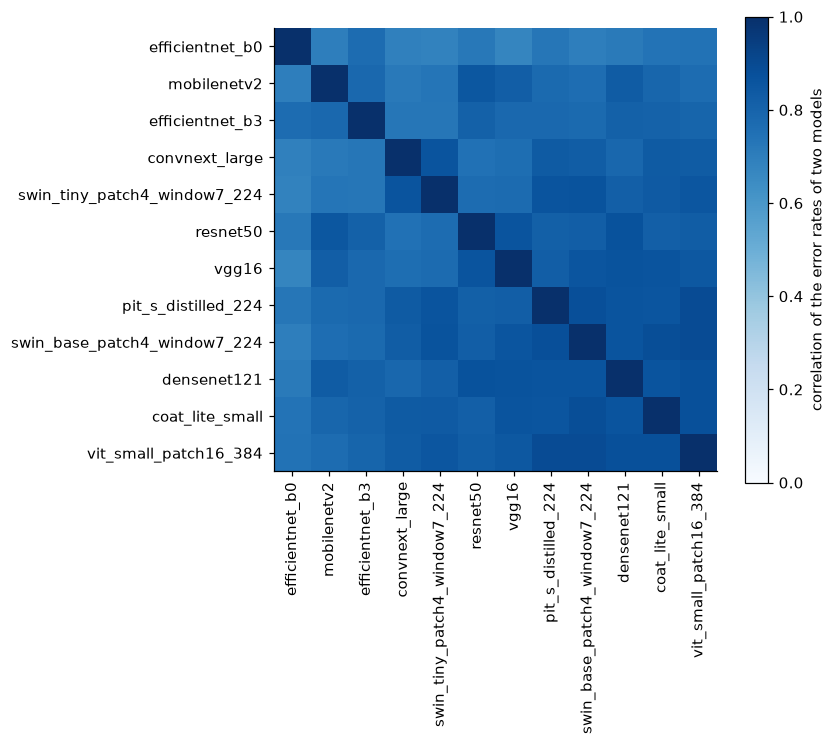

In [14]:
model_of = data.drop_duplicates("run").set_index("run")["model"].loc[wrong.index]
correlation = wrong.astype(float).T.corr()
same_model = model_of.to_numpy()[:, None] == model_of.to_numpy()[None, :]
not_diagonal = ~np.eye(len(correlation), dtype=bool)
print(f"two runs of the same model: {correlation.to_numpy()[same_model & not_diagonal].mean():.2f}")
print(f"two runs of different models: {correlation.to_numpy()[~same_model].mean():.2f}")

by_model = wrong.groupby(model_of.to_numpy()).mean().T.corr()
order = by_model.mean().sort_values().index
plt.figure(figsize=(6.5, 5.5))
plt.imshow(by_model.loc[order, order], cmap="Blues", vmin=0, vmax=1)
plt.xticks(range(len(order)), order, rotation=90)
plt.yticks(range(len(order)), order)
plt.colorbar(label="correlation of the error rates of two models")
plt.show()

## 5. Which patches, which pictures, which patients?

Where the errors collect. The error rate is the share of the 60 runs that get a patch wrong.

In [33]:
print("Error rate by true class:")
display(patches.groupby("true_name")["error_rate"].agg(["mean", "size"]).round(3))
print("Error rate by true class and by the NDB-UFES diagnosis of the picture:")
display(patches.pivot_table(index="true_name", columns="ndb", values="error_rate", aggfunc="mean").round(2))
print("and how many patches are in each of those groups:")
display(patches.pivot_table(index="true_name", columns="ndb", values="error_rate", aggfunc="size"))

mostly_wrong = patches[patches["error_rate"] >= 0.8].index
direction = data[data["wrong"] & data["patch_id"].isin(mostly_wrong)].groupby("patch_id")["pred_name"].agg(lambda s: s.mode()[0])
print(f"The {len(mostly_wrong)} patches that are wrong in at least 80% of the runs: what they are, and what the models call them")
display(pd.crosstab(patches.loc[mostly_wrong, "true_name"], direction.rename("usually called")))

Error rate by true class:


,mean,size
true_name,,
OSCC,0.380,189
With dysplasia,0.512,355
Without dysplasia,0.364,112


Error rate by true class and by the NDB-UFES diagnosis of the picture:


ndb,Leukoplakia with dysplasia,Leukoplakia without dysplasia,OSCC,not in NDB-UFES
true_name,,,,
OSCC,NaN,NaN,0.21,0.96
With dysplasia,0.35,0.23,0.88,0.39
Without dysplasia,0.36,0.29,NaN,0.79


and how many patches are in each of those groups:


ndb,Leukoplakia with dysplasia,Leukoplakia without dysplasia,OSCC,not in NDB-UFES
true_name,,,,
OSCC,NaN,NaN,146.0,43.0
With dysplasia,114.0,67.0,118.0,56.0
Without dysplasia,53.0,49.0,NaN,10.0


The 197 patches that are wrong in at least 80% of the runs: what they are, and what the models call them


usually called,OSCC,With dysplasia,Without dysplasia
true_name,,,
OSCC,0,57,0
With dysplasia,116,0,11
Without dysplasia,8,5,0


In [34]:
def share_explained(column: str) -> float:
    """How much of the differences between the error rates of the patches is the difference between the groups (pictures or patients): 0 none, 1 all."""
    total = ((patches["error_rate"] - patches["error_rate"].mean()) ** 2).sum()
    within = ((patches["error_rate"] - patches.groupby(column)["error_rate"].transform("mean")) ** 2).sum()
    return 1 - within / total


print(f"Differences between the patches explained by their picture: {share_explained('histopath_id'):.0%}")
print(f"Differences between the patches explained by their patient: {share_explained('case_group'):.0%}")

pictures = patches.groupby("histopath_id").agg(patches=("errors", "size"), error_rate=("error_rate", "mean"), true_label=("true_name", lambda s: s.mode()[0]), ndb_diagnosis=("ndb", "first")).sort_values("error_rate", ascending=False)
pictures["error_rate"] = pictures["error_rate"].round(2)
print("The pictures, from the most wrong to the least wrong:")
display(pictures)

Differences between the patches explained by their picture: 76%
Differences between the patches explained by their patient: 44%
The pictures, from the most wrong to the least wrong:


,patches,error_rate,true_label,ndb_diagnosis
histopath_id,,,,
hp_7015fbba1516,20,0.99,With dysplasia,OSCC
hp_ef29b44759fb,19,0.95,With dysplasia,Leukoplakia with dysplasia
hp_887b5a2ab8c2,16,0.93,With dysplasia,OSCC
hp_b9d6e3d0d4e2,16,0.93,With dysplasia,OSCC
hp_45fa29fc9f69,20,0.91,With dysplasia,OSCC
hp_22608f5c7482,20,0.84,OSCC,not in NDB-UFES
hp_c5d4056c7d28,17,0.83,With dysplasia,OSCC
hp_3125445e31bd,20,0.82,OSCC,OSCC
hp_f2c88f0423cc,20,0.79,With dysplasia,OSCC


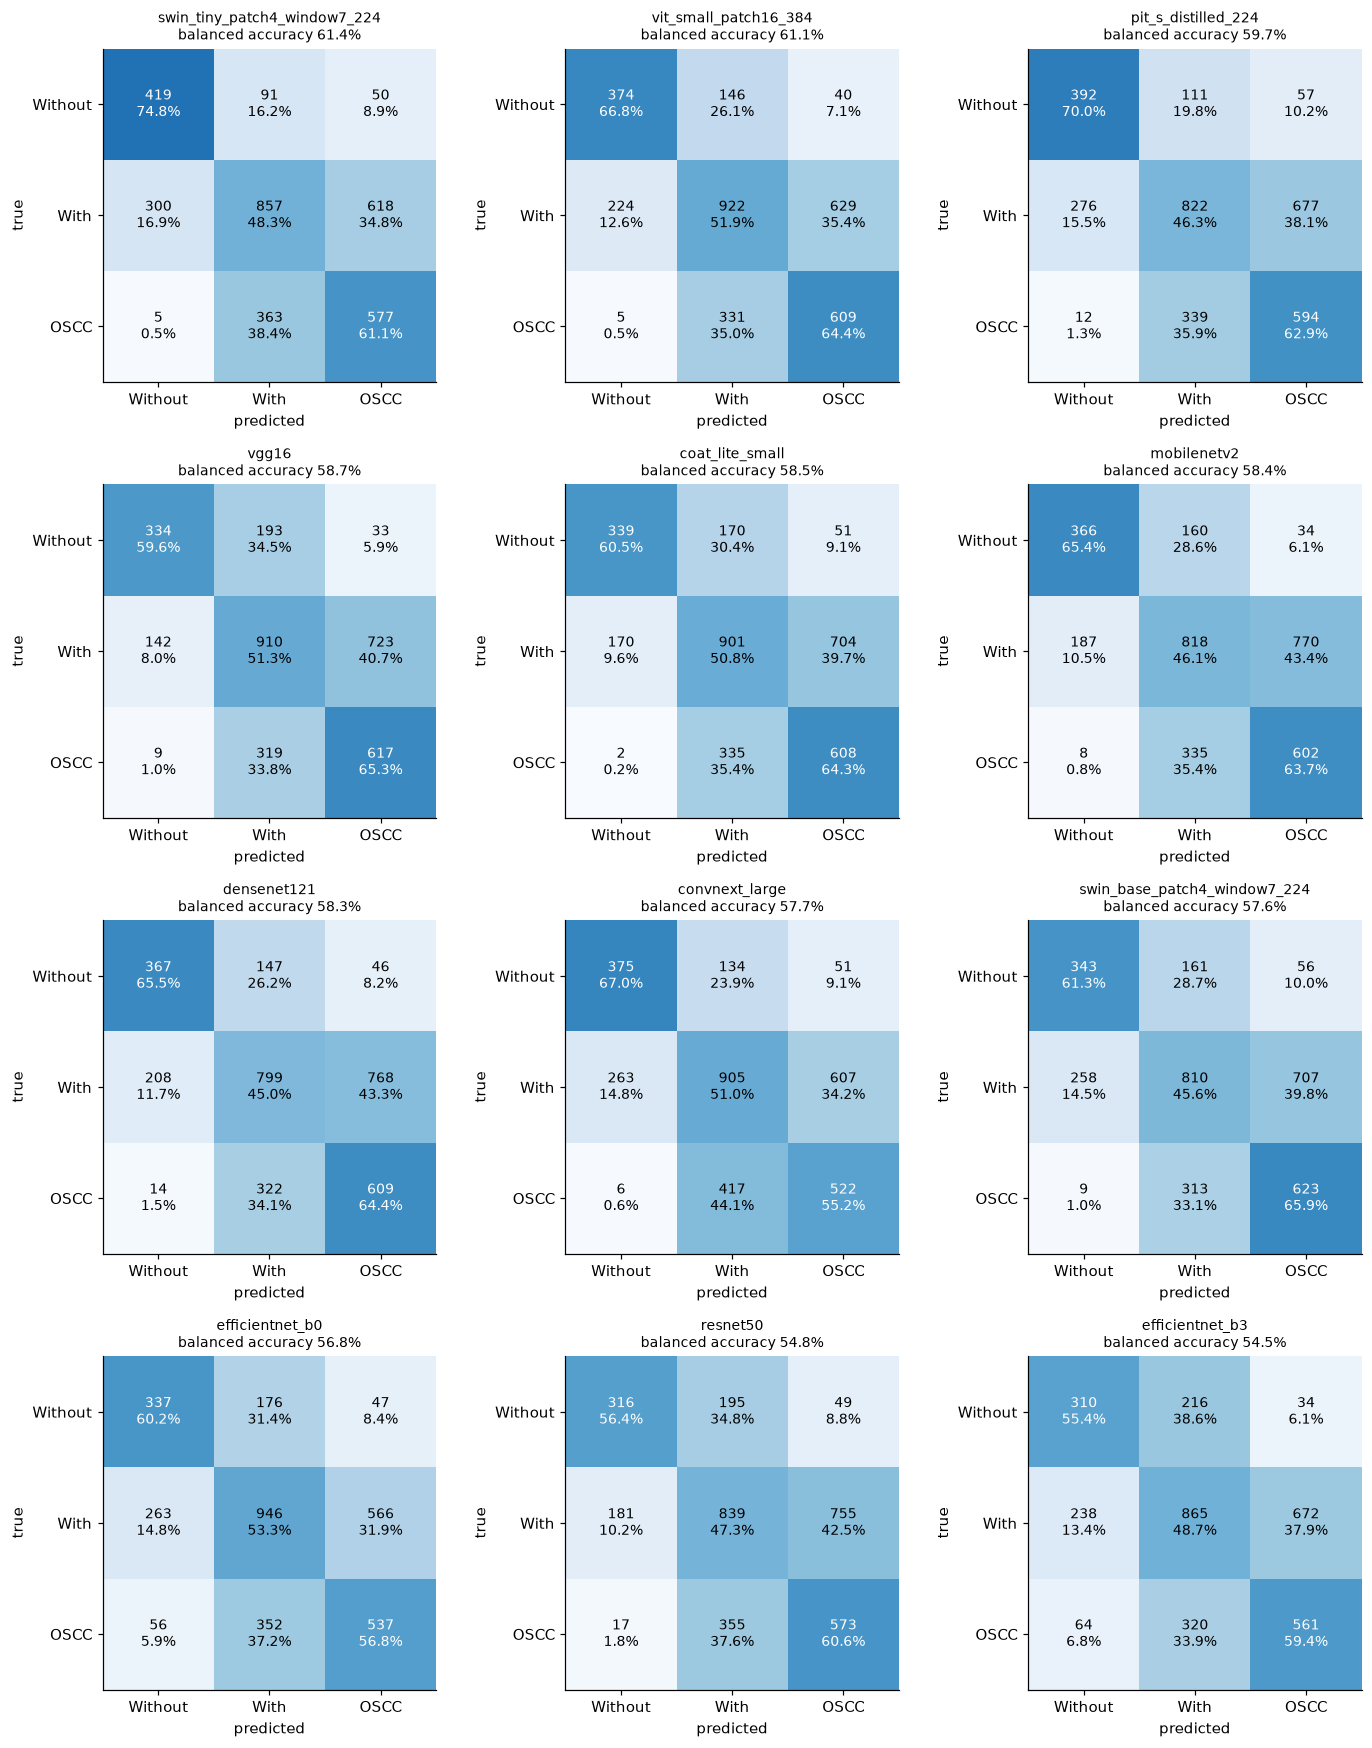

In [38]:
from sklearn.metrics import confusion_matrix

CLASS_SHORT = ["Without", "With", "OSCC"]
FOLD = None  # None: the five fold runs of each model added up; or 0 to 4 to see one fold run


def matrices(frame):
    """For each model: the confusion matrix as counts (rows: true class, columns: predicted class) and as the percentage of each true class."""
    result = {}
    for model, group in frame.groupby("model"):
        if FOLD is not None:
            group = group[group["validation_fold"] == FOLD]
        counts = confusion_matrix(group["y_true"], group["y_pred"], labels=[0, 1, 2])
        result[model] = (counts, counts / counts.sum(axis=1, keepdims=True) * 100)
    return result


mats = matrices(data)
order = sorted(mats, key=lambda model: -np.mean(np.diag(mats[model][1])))  # best balanced accuracy first

columns = 3
rows = int(np.ceil(len(order) / columns))
fig, axes = plt.subplots(rows, columns, figsize=(4.3 * columns, 4.0 * rows), squeeze=False)
for axis in axes.ravel():
    axis.axis("off")
for axis, model in zip(axes.ravel(), order):
    counts, percent = mats[model]
    axis.axis("on")
    axis.imshow(percent, cmap="Blues", vmin=0, vmax=100)
    for i in range(3):
        for j in range(3):
            axis.text(j, i, f"{counts[i, j]}\n{percent[i, j]:.1f}%", ha="center", va="center", fontsize=9, color="white" if percent[i, j] > 55 else "black")
    axis.set_xticks(range(3), CLASS_SHORT)
    axis.set_yticks(range(3), CLASS_SHORT)
    axis.set_xlabel("predicted")
    axis.set_ylabel("true")
    axis.set_title(f"{model}\nbalanced accuracy {np.mean(np.diag(percent)):.1f}%", fontsize=9)
plt.tight_layout()
plt.show()

,best fold,best %,mean %,worst fold,worst %
swin_tiny_patch4_window7_224,3.0,64.0,61.4,2.0,59.6
vit_small_patch16_384,2.0,64.3,61.1,0.0,55.5
pit_s_distilled_224,4.0,62.0,59.7,2.0,55.0
vgg16,0.0,61.5,58.7,4.0,56.1
coat_lite_small,1.0,61.2,58.5,4.0,54.5
mobilenetv2,3.0,61.7,58.4,4.0,54.5
densenet121,3.0,62.4,58.3,0.0,52.9
convnext_large,3.0,61.5,57.7,0.0,54.4
swin_base_patch4_window7_224,2.0,62.5,57.6,4.0,52.2
efficientnet_b0,1.0,59.9,56.8,2.0,51.8


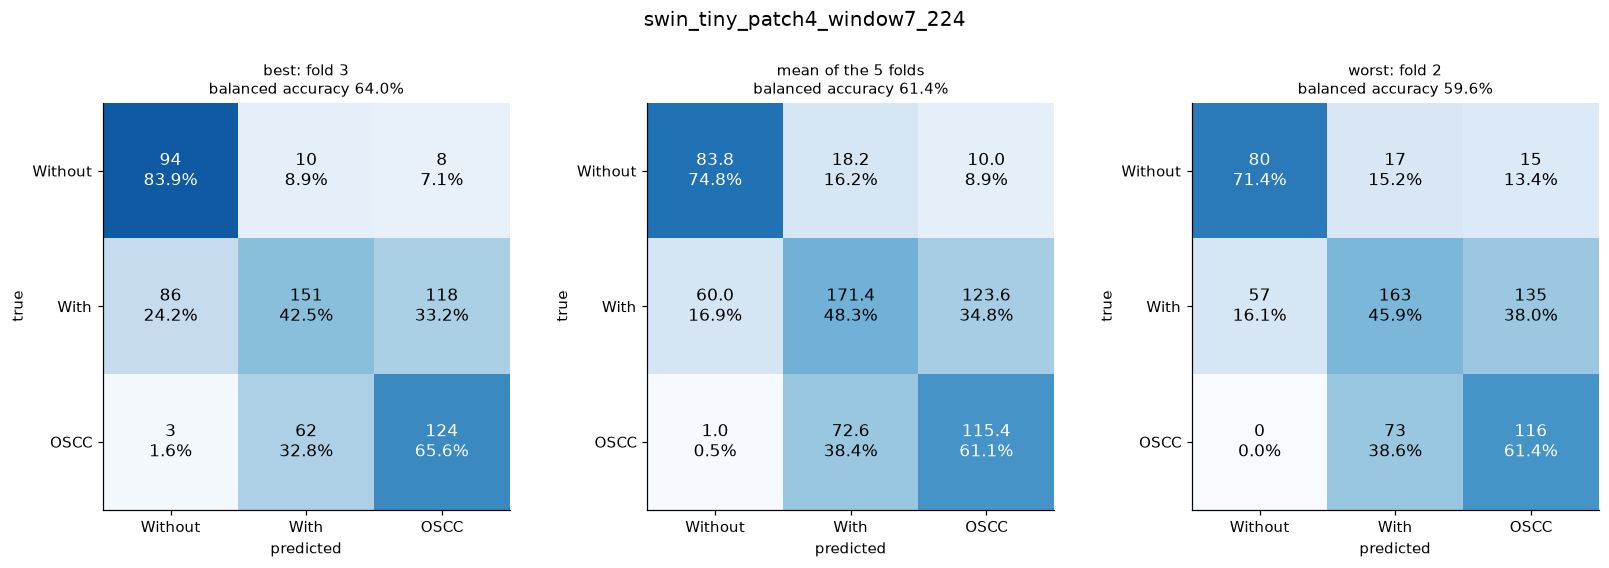

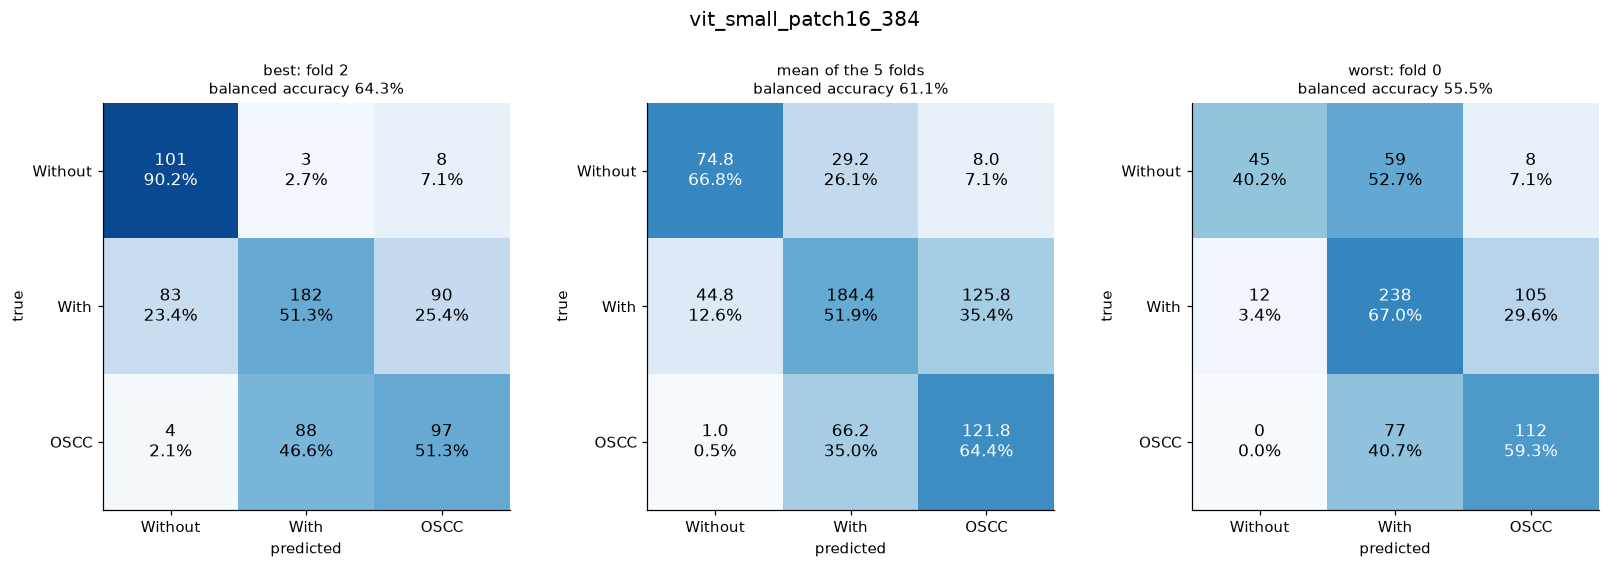

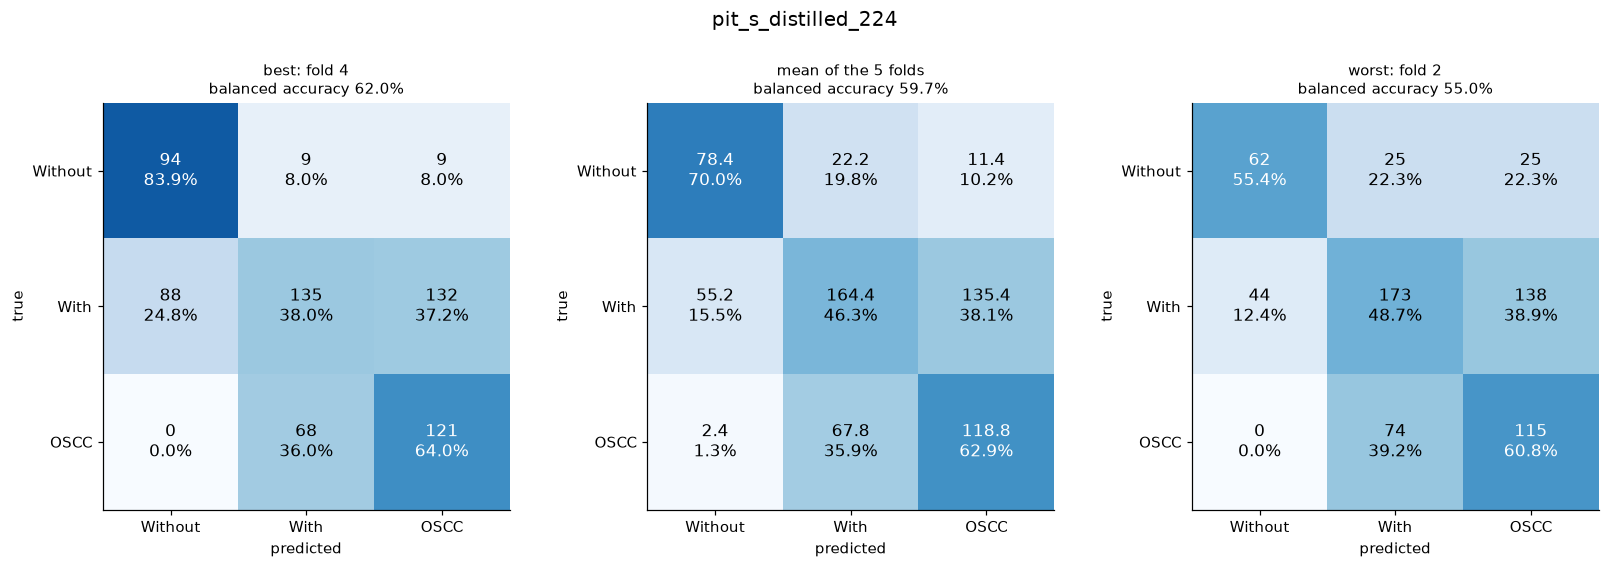

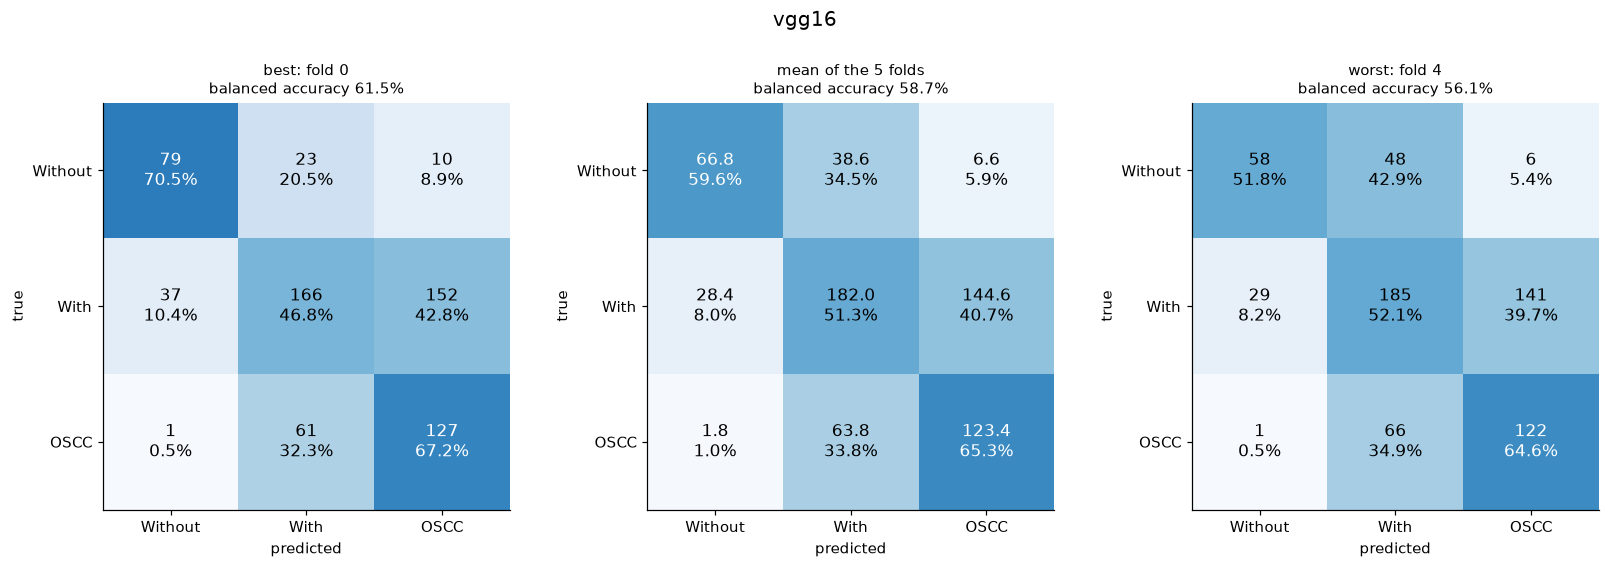

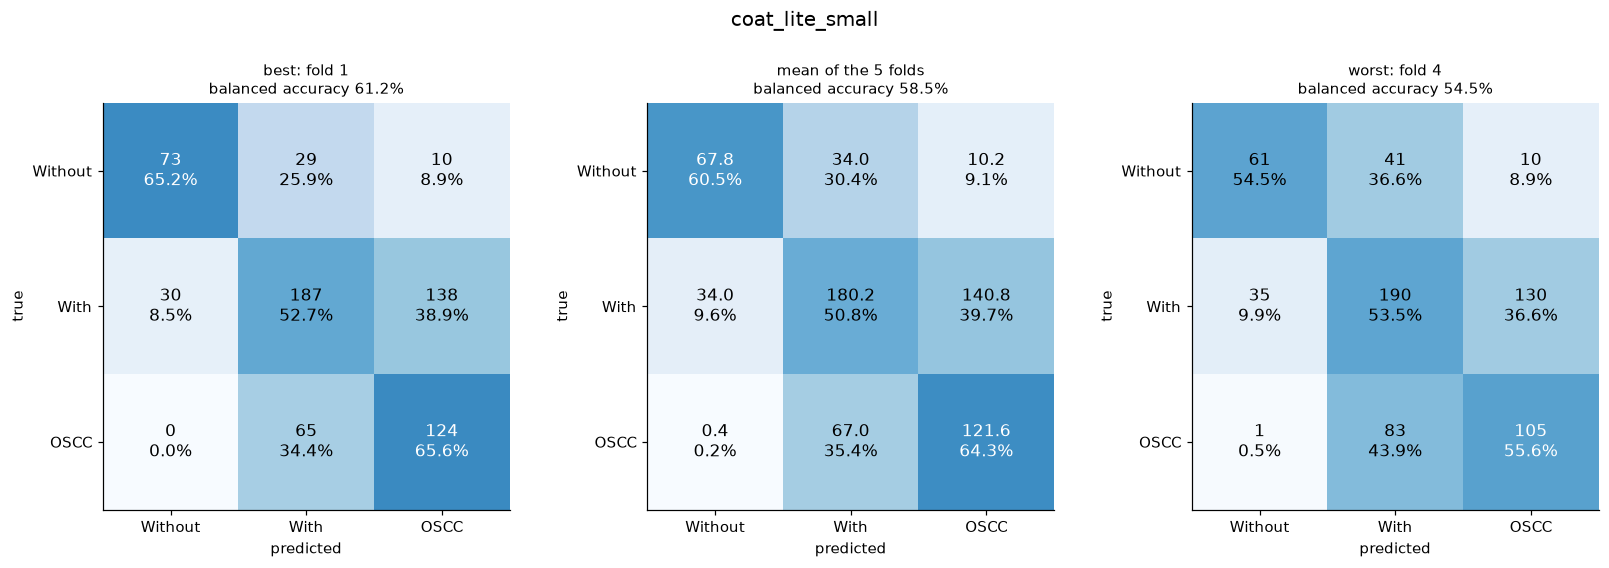

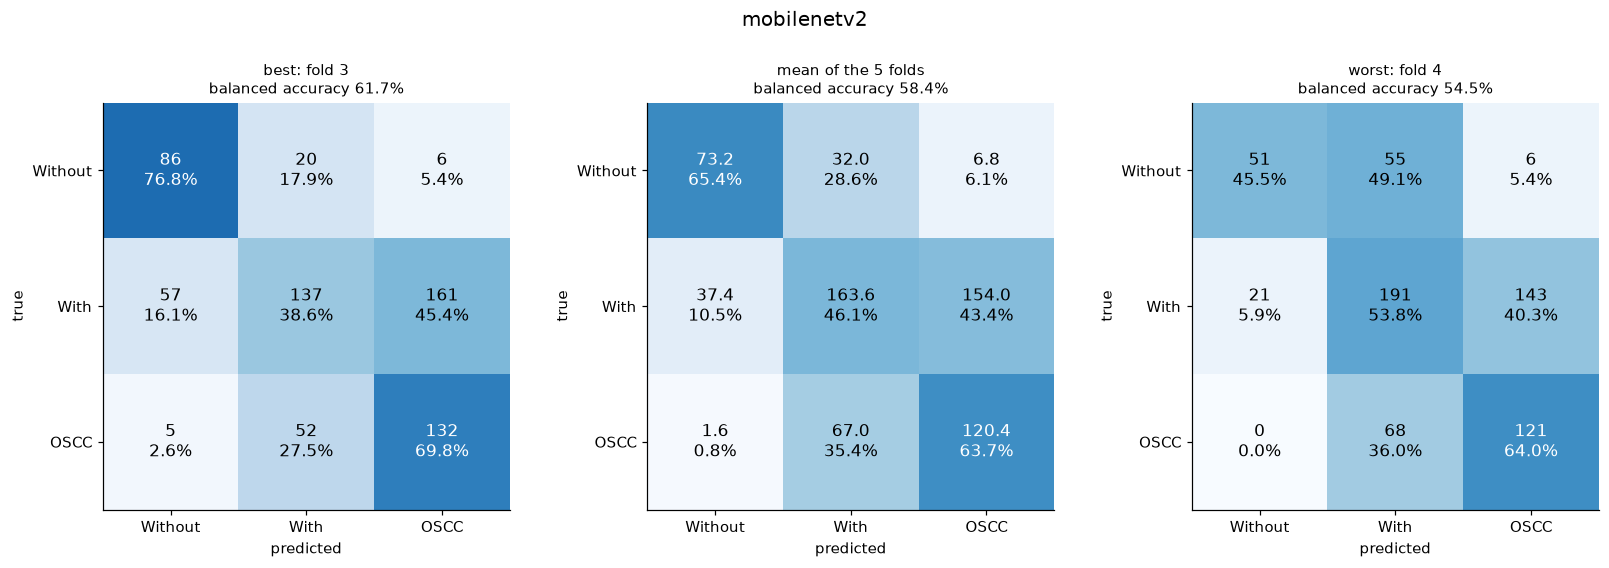

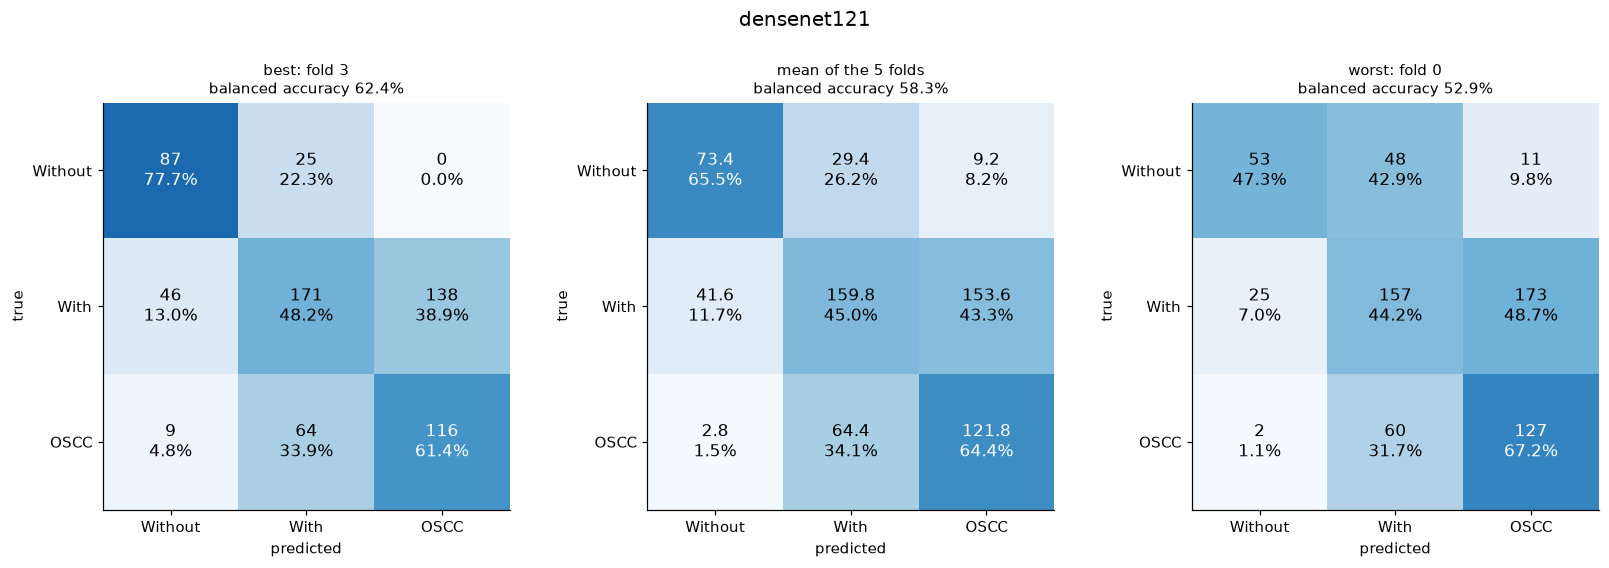

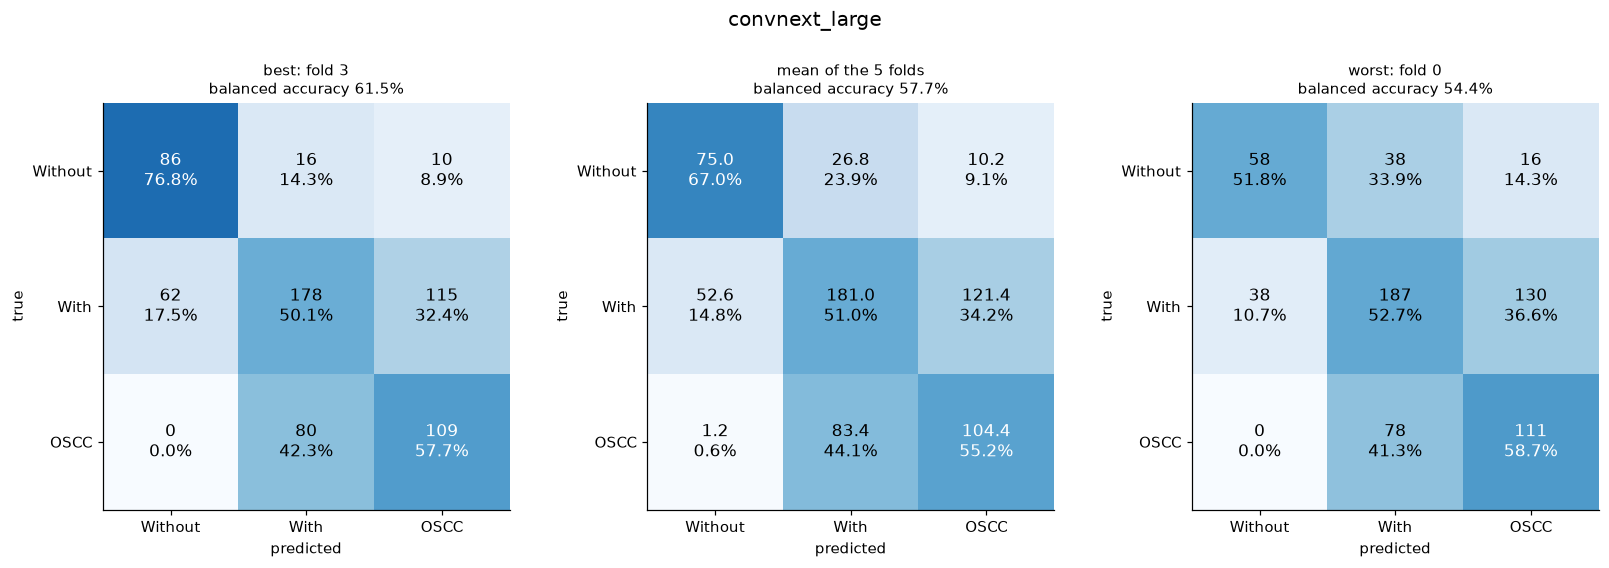

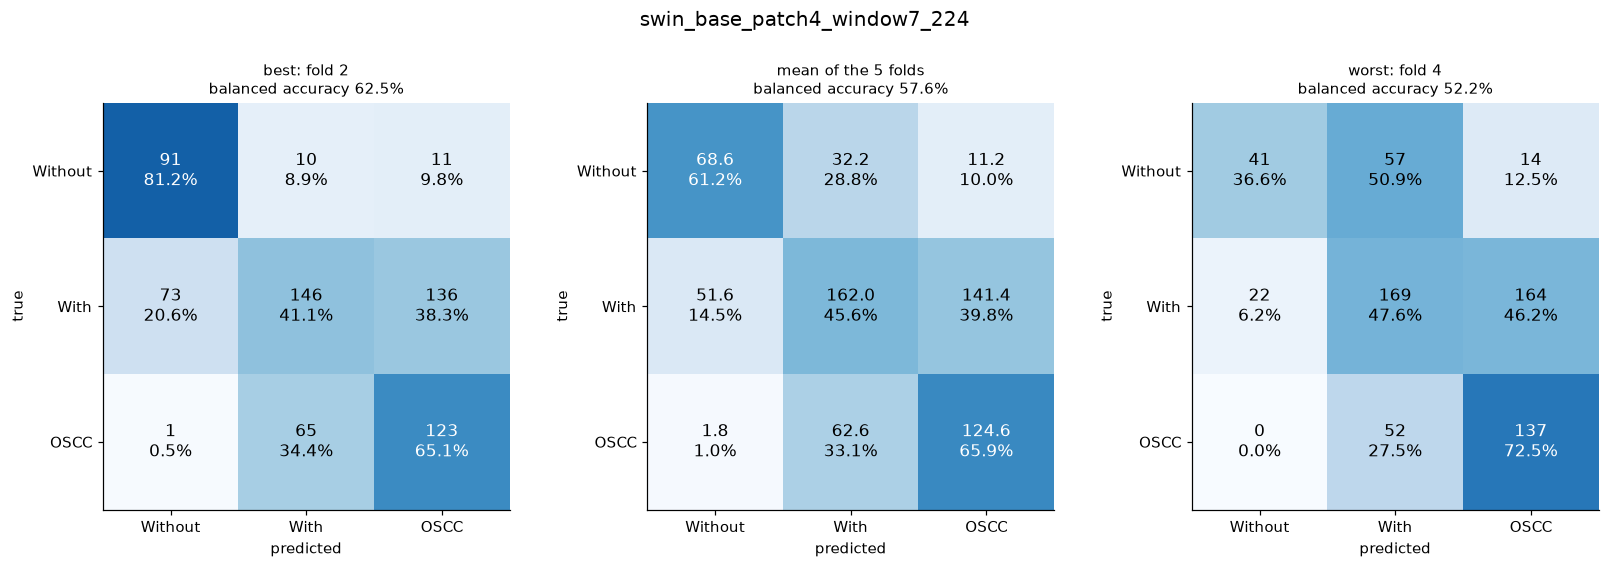

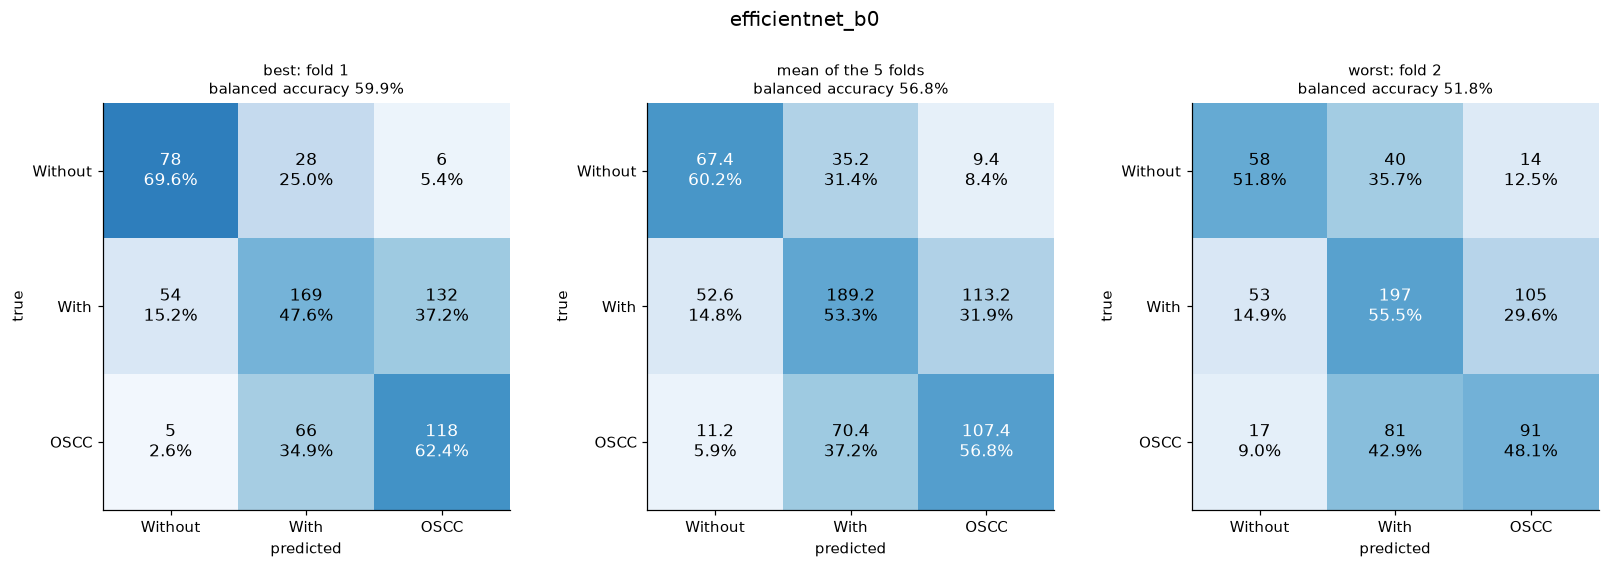

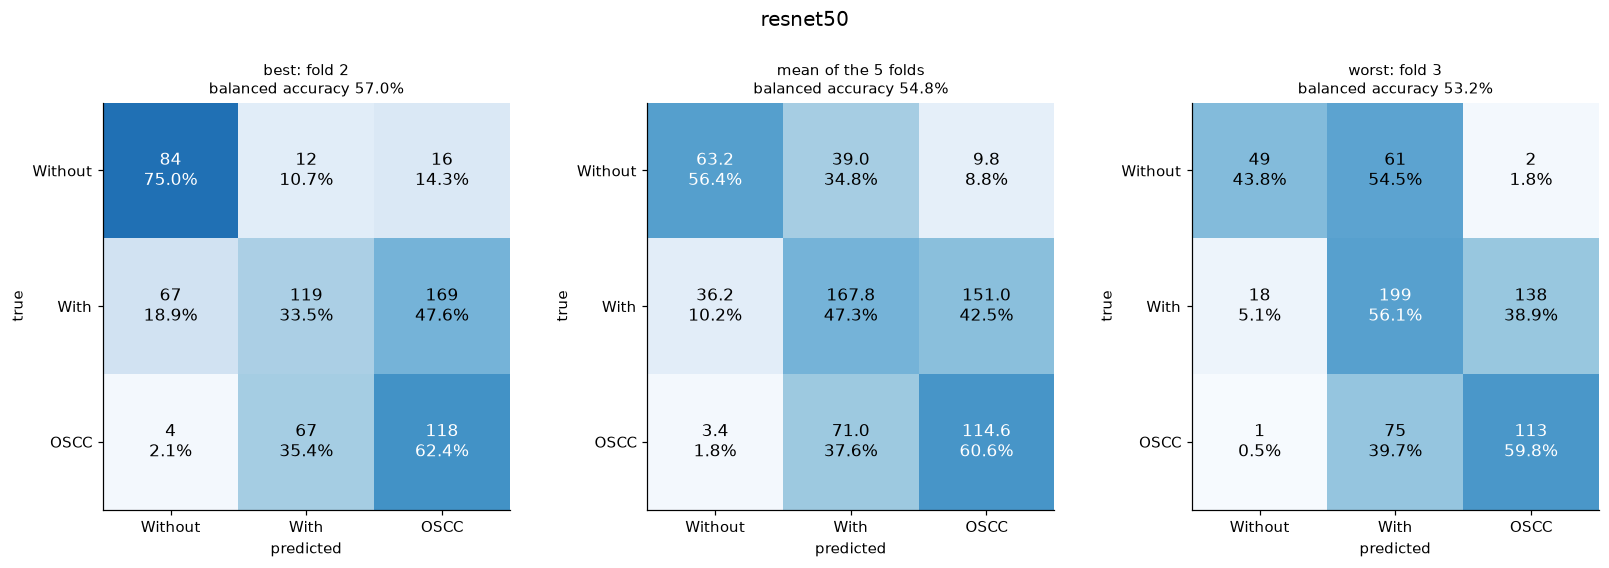

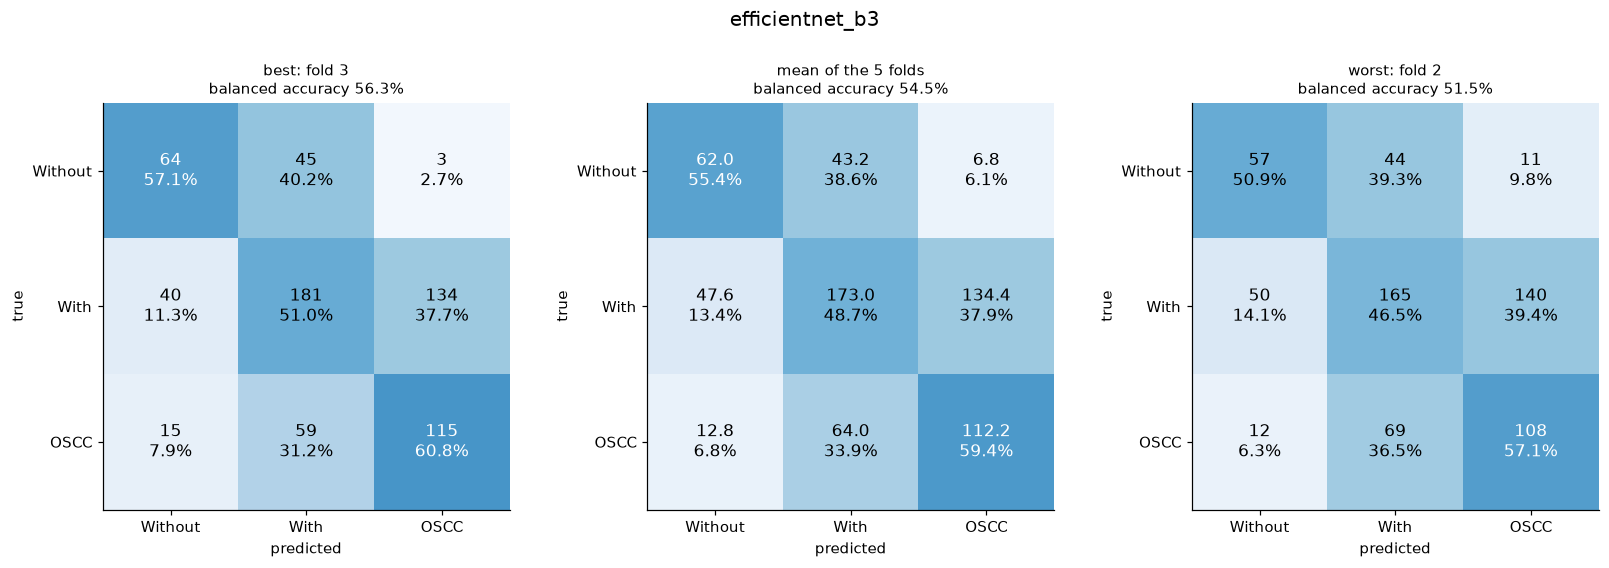

In [41]:
from sklearn.metrics import confusion_matrix

CLASS_SHORT = ["Without", "With", "OSCC"]


def as_percent(counts):
    return counts / counts.sum(axis=1, keepdims=True) * 100  # the percentage of each true class: a row adds to 100


def draw_matrix(axis, counts, percent, title, decimals=0):
    """One confusion matrix: the count and the percentage of the true class in each cell."""
    axis.imshow(percent, cmap="Blues", vmin=0, vmax=100)
    for i in range(3):
        for j in range(3):
            axis.text(j, i, f"{counts[i, j]:.{decimals}f}\n{percent[i, j]:.1f}%", ha="center", va="center", fontsize=11, color="white" if percent[i, j] > 55 else "black")
    axis.set_xticks(range(3), CLASS_SHORT)
    axis.set_yticks(range(3), CLASS_SHORT)
    axis.set_xlabel("predicted")
    axis.set_ylabel("true")
    axis.set_title(f"{title}\nbalanced accuracy {np.mean(np.diag(percent)):.1f}%", fontsize=10)


# for each model: the confusion matrix of each of its fold runs
runs_by_model = {model: {fold: confusion_matrix(group["y_true"], group["y_pred"], labels=[0, 1, 2]) for fold, group in frame.groupby("validation_fold")} for model, frame in data.groupby("model")}
balanced_by_model = {model: {fold: np.mean(np.diag(as_percent(counts))) for fold, counts in runs.items()} for model, runs in runs_by_model.items()}
order_by_score = sorted(balanced_by_model, key=lambda model: -np.mean(list(balanced_by_model[model].values())))  # best model first

summary_folds = pd.DataFrame({
    model: {"best fold": max(scores, key=scores.get), "best %": max(scores.values()), "mean %": np.mean(list(scores.values())), "worst fold": min(scores, key=scores.get), "worst %": min(scores.values())}
    for model, scores in balanced_by_model.items()
}).T.loc[order_by_score].round(1)
display(summary_folds)

for model in order_by_score:
    runs, scores = runs_by_model[model], balanced_by_model[model]
    best_fold, worst_fold = max(scores, key=scores.get), min(scores, key=scores.get)
    mean_counts = np.mean(list(runs.values()), axis=0)  # the mean over the folds of the model
    panels = [(f"best: fold {best_fold}", runs[best_fold], 0), (f"mean of the {len(runs)} folds", mean_counts, 1), (f"worst: fold {worst_fold}", runs[worst_fold], 0)]
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for axis, (title, counts, decimals) in zip(axes, panels):
        draw_matrix(axis, counts, as_percent(counts), title, decimals)
    fig.suptitle(model, fontsize=13)
    plt.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()

In [39]:
labels = [f"{true}→{predicted}" for true in CLASS_SHORT for predicted in CLASS_SHORT]
table = pd.DataFrame({model: [f"{counts[i, j]} ({percent[i, j]:.1f}%)" for i in range(3) for j in range(3)] for model, (counts, percent) in mats.items()}, index=labels).T.loc[order]
display(table)

,Without→Without,Without→With,Without→OSCC,With→Without,With→With,With→OSCC,OSCC→Without,OSCC→With,OSCC→OSCC
swin_tiny_patch4_window7_224,419 (74.8%),91 (16.2%),50 (8.9%),300 (16.9%),857 (48.3%),618 (34.8%),5 (0.5%),363 (38.4%),577 (61.1%)
vit_small_patch16_384,374 (66.8%),146 (26.1%),40 (7.1%),224 (12.6%),922 (51.9%),629 (35.4%),5 (0.5%),331 (35.0%),609 (64.4%)
pit_s_distilled_224,392 (70.0%),111 (19.8%),57 (10.2%),276 (15.5%),822 (46.3%),677 (38.1%),12 (1.3%),339 (35.9%),594 (62.9%)
vgg16,334 (59.6%),193 (34.5%),33 (5.9%),142 (8.0%),910 (51.3%),723 (40.7%),9 (1.0%),319 (33.8%),617 (65.3%)
coat_lite_small,339 (60.5%),170 (30.4%),51 (9.1%),170 (9.6%),901 (50.8%),704 (39.7%),2 (0.2%),335 (35.4%),608 (64.3%)
mobilenetv2,366 (65.4%),160 (28.6%),34 (6.1%),187 (10.5%),818 (46.1%),770 (43.4%),8 (0.8%),335 (35.4%),602 (63.7%)
densenet121,367 (65.5%),147 (26.2%),46 (8.2%),208 (11.7%),799 (45.0%),768 (43.3%),14 (1.5%),322 (34.1%),609 (64.4%)
convnext_large,375 (67.0%),134 (23.9%),51 (9.1%),263 (14.8%),905 (51.0%),607 (34.2%),6 (0.6%),417 (44.1%),522 (55.2%)
swin_base_patch4_window7_224,343 (61.3%),161 (28.7%),56 (10.0%),258 (14.5%),810 (45.6%),707 (39.8%),9 (1.0%),313 (33.1%),623 (65.9%)
efficientnet_b0,337 (60.2%),176 (31.4%),47 (8.4%),263 (14.8%),946 (53.3%),566 (31.9%),56 (5.9%),352 (37.2%),537 (56.8%)


## 6. Look at the patches

`show` draws patches with their label, what the models usually say, and how often they are wrong. First the patches that are wrong almost always, then, for contrast, patches of the same class that are almost never wrong.

Wrong in the most runs:


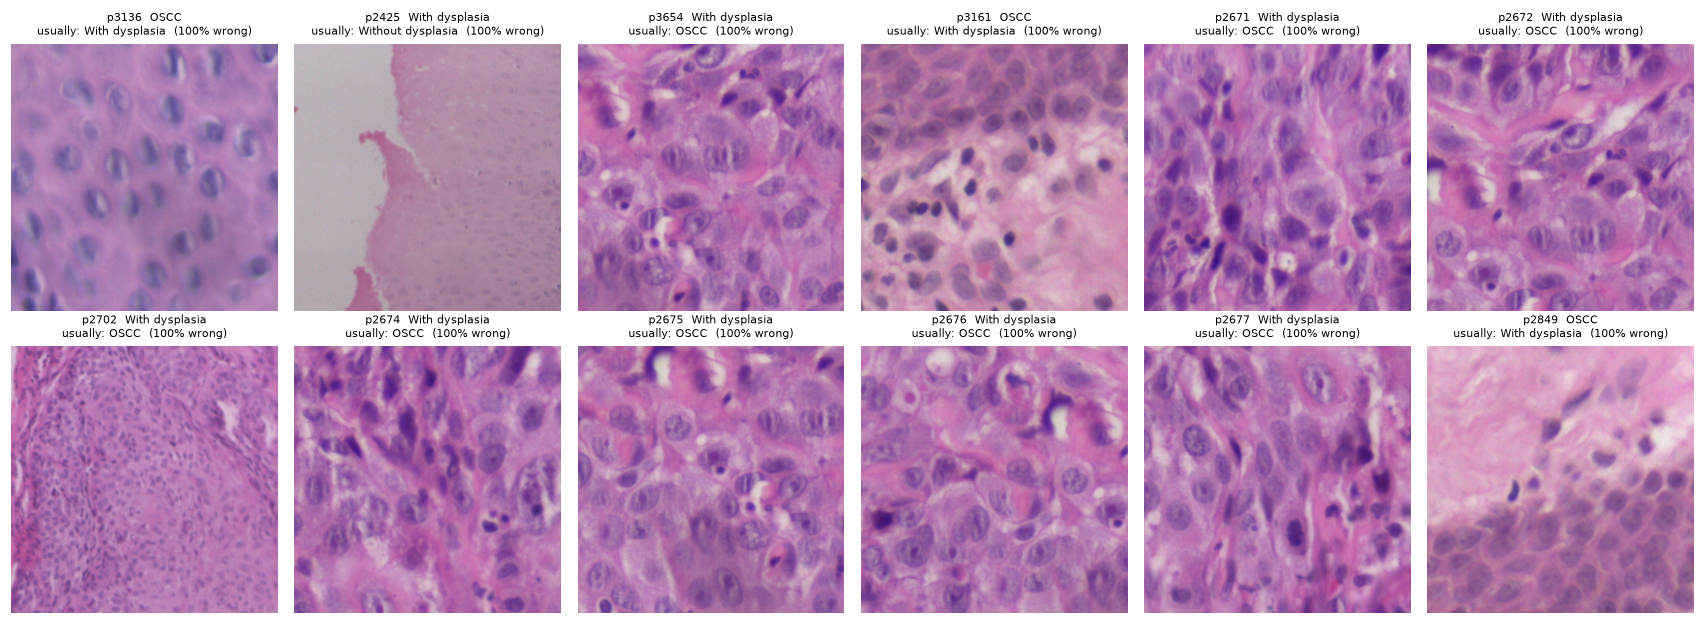

In [35]:
usual = data[data["wrong"]].groupby("patch_id")["pred_name"].agg(lambda s: s.mode()[0])


def show(patch_ids, columns: int = 6) -> None:
    patch_ids = list(patch_ids)
    rows = int(np.ceil(len(patch_ids) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(2.6 * columns, 2.9 * rows), squeeze=False)
    for axis in axes.ravel():
        axis.axis("off")
    for axis, patch_id in zip(axes.ravel(), patch_ids):
        axis.imshow(Image.open(PATCHES / f"{patch_id}.png"))
        axis.set_title(f"{patch_id}  {patches.loc[patch_id, 'true_name']}\nusually: {usual.get(patch_id, '-')}  ({patches.loc[patch_id, 'error_rate']:.0%} wrong)", fontsize=7)
    plt.tight_layout()
    plt.show()


print("Wrong in the most runs:")
show(patches.sort_values("error_rate", ascending=False).head(12).index)

Patches labeled with dysplasia that are almost never wrong:


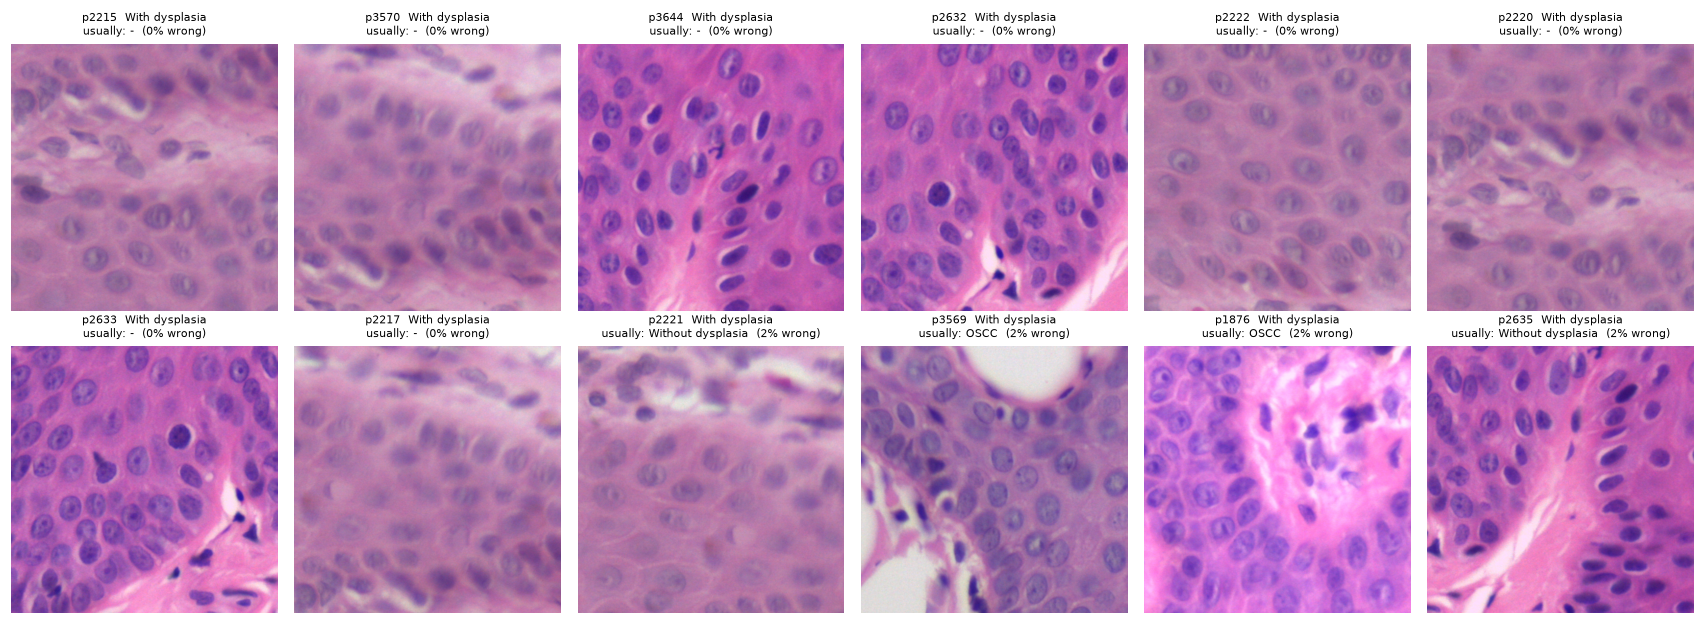

In [36]:
same_class = patches["true_name"] == "With dysplasia"
print("Patches labeled with dysplasia that are almost never wrong:")
show(patches[same_class].sort_values("error_rate").head(12).index)

## 7. Does combining the models help?

Average the probabilities of all 60 runs and take the most likely class. If the models made different mistakes, the average would be much better than any one of them. If the mistakes are shared, it helps little.

In [37]:
mean_probabilities = data.groupby("patch_id")[PROBABILITIES].mean().loc[patches.index]
ensemble = mean_probabilities.to_numpy().argmax(axis=1)
ensemble_score = balanced_accuracy_score(patches["y_true"], ensemble)
print(f"All 60 runs averaged: balanced accuracy {ensemble_score * 100:.1f}%")
print(f"A single run: {balanced.mean() * 100:.1f}% on average, from {balanced.min() * 100:.1f}% to {balanced.max() * 100:.1f}%")
matrix = pd.crosstab(patches["true_name"], pd.Series(ensemble, index=patches.index).map(dict(enumerate(CLASSES))).rename("predicted"))
display(matrix)
display((matrix.div(matrix.sum(axis=1), axis=0) * 100).round(1))

All 60 runs averaged: balanced accuracy 65.3%
A single run: 58.1% on average, from 51.5% to 64.3%


predicted,OSCC,With dysplasia,Without dysplasia
true_name,,,
OSCC,123,66,0
With dysplasia,138,186,31
Without dysplasia,8,16,88


predicted,OSCC,With dysplasia,Without dysplasia
true_name,,,
OSCC,65.1,34.9,0.0
With dysplasia,38.9,52.4,8.7
Without dysplasia,7.1,14.3,78.6


## 8. Play

Some things to try (the data frames are `data`, one row per patch and run; `patches`, one row per patch; `pictures`; `wrong`, runs by patches):

* the errors of one model: `data[data["model"] == "vgg16"]`
* the patches of one picture: `patches[patches["histopath_id"] == "hp_..."]`, then `show(...)` them
* the patches that only the transformers get wrong: compare `wrong.loc[wrong.index.str.startswith(("swin", "vit", "pit", "coat"))]` with the rest
* change `EXPERIMENT` to `ndb_ufes_exp1` and run again from the top to see the same questions on the old folds